# Medical Abstract Classification with BiLSTM and Word Embeddings

Classifies medical abstracts into five disease categories using a bidirectional LSTM, and compares two embedding choices: **FastText** trained on this corpus versus pretrained **BioWordVec** biomedical embeddings.

Sections: 1. Dataset processing, 2. Word embedding construction, 3. Visualisation, 4. BiLSTM model, 5. Evaluation, 6. Interactive inference.


## How to run

See the repository `README.md` for setup. In short: put the dataset CSVs and the BioWordVec file in a `data/` folder next to this notebook, install the packages in `requirements.txt`, then run all cells. Trained weights are saved to `models/`, which section 6 uses for interactive predictions without retraining.

Works locally or in Google Colab (in Colab, set `DATA_DIR` to your Drive folder).


# 1. Dataset Processing

Data preprocessing steps contain the following methods:

- **Unicode normalisation & lowercasing**
- **Biomedical-friendly cleanup** (keep `-` and `.`; remove other symbols)
- **Tokenisation**
- **Stopword filtering** (retain negations: `no`, `not`, `nor`, `without`)
- **Lemmatisation** (WordNet)
- **Build `clean_text`** for train/test
- **Robust label mapping → `label_id`** (accept code or full name)
- **Vocabulary & numericalisation** (train-only vocab, `min_count=2`, add `<pad>`/`<unk>`)
- **Sanity checks** (before/after examples, label distribution)


In [1]:
%pip install -q gensim

In [2]:
# Import all necessary packages
import re
import pandas as pd
import numpy as np

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize


In [3]:
# Download required NLTK assets only if missing
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [4]:
# Data location: defaults to ./data (see README). In Colab, mount Drive and point DATA_DIR there.
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # running locally

DATA_DIR = os.environ.get("DATA_DIR", "data")

TRAIN_PATH  = f"{DATA_DIR}/medical_tc_train.csv"
TEST_PATH   = f"{DATA_DIR}/medical_tc_test.csv"
LABELS_PATH = f"{DATA_DIR}/medical_tc_labels.csv"


In [5]:
train_df  = pd.read_csv(TRAIN_PATH)
test_df   = pd.read_csv(TEST_PATH)
labels_df = pd.read_csv(LABELS_PATH)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Labels :", labels_df.shape[0], "classes")


Train shape: (11550, 2)
Test shape : (2888, 2)
Labels : 5 classes


Read the three CSVs:
  - `train_df` and `test_df` contain the raw abstracts and their labels.
  - `labels_df` holds the label mapping (`condition_label` ↔ `condition_name`).

`Train shape: (11550, 2)`  
  → the training set has **11,550 rows** (abstracts) and **2 columns**.

`Test shape: (2888, 2)`  
  → the test set has **2,888 rows** and **2 columns**.

`Labels : 5 classes`  
  → there are **5 distinct target classes** defined in `labels_df`.


After creating the preprocessing variables, the following procedures are undertaken

- **Stopword set with preserved negations**  
  Build the English stopword list but **retain** `no`, `not`, and `nor` so clinically important negation is not discarded during filtering.

- **WordNet lemmatiser initialisation**  
  Prepare a lemmatiser to reduce inflected forms to their base form (e.g., *patients → patient*, *studies → study*), lowering vocabulary sparsity.

- **`basic_normalise(text)` — light, biomedical-friendly normalisation**  
  - Convert to lowercase and apply simple character filtering.  
  - **Keep hyphens and periods** so terms like *COVID-19*, *p-value*, and decimals remain intact.  
  - Fix spaced decimals (`3 . 5 → 3.5`) and collapse extra whitespace.

- **`preprocess_text(text)` — end-to-end cleaning pipeline**  
  1) Run `basic_normalise`.  
  2) **Tokenise** the text.  
  3) **Remove stopwords** (negations preserved).  
  4) **Lemmatise** tokens.  
  5) **Rejoin** tokens into a single `clean_text` string.



In [6]:
# Stopwords set with preserved negations
_stop = set(stopwords.words('english'))
for keep in ["no", "not", "nor"]:
    if keep in _stop:
        _stop.remove(keep)

lemmatizer = WordNetLemmatizer()

def basic_normalise(text: str) -> str:
    # Lower case
    text = str(text).lower()
    # Replace non-allowed chars with space (allow a–z, 0–9, hyphen, dot)
    text = re.sub(r"[^a-z0-9\-\.\s]", " ", text)
    # Fix spaced decimals like "3 . 5" -> "3.5"
    text = re.sub(r"\s+\.\s+", ".", text)
    # Collapse whitespace
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_text(text: str) -> str:
    # Tokenise -> remove stopwords (keeping 'no/not/nor') -> lemmatise -> rejoin

    text = basic_normalise(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in _stop]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)


Preprocessing application and label indexing

- Apply `preprocess_text` to the `medical_abstract` field in both training and test sets, producing a `clean_text` column used for tokenisation, vocabulary construction, and modelling.
- Construct a deterministic mapping from `condition_label` to integer class indices (`label2id`) and the corresponding reverse mapping (`id2label`) from `labels_df`.
- Encode training targets by adding `label_id` to `train_df` according to the mapping. (Test labels are mapped at evaluation time.)
- Print concise sanity outputs: two raw vs. cleaned snippets and the per-class counts for `label_id`.


In [7]:
# Apply to train/test; this can take a minute for large data
train_df["clean_text"] = train_df["medical_abstract"].apply(preprocess_text)
test_df["clean_text"]  = test_df["medical_abstract"].apply(preprocess_text)

# Build label mapping from the provided list to stable indices
label_list = labels_df["condition_label"].tolist()
label2id = {lbl: i for i, lbl in enumerate(label_list)}
id2label = {i: lbl for lbl, i in label2id.items()}

# Map train labels to integers (assumes column name 'label' in train_df)
train_df["label_id"] = train_df["condition_label"].map(label2id)

# Quick sanity checks
print("Example before/after:")
for i in range(2):
    print(f"\nRaw:   {train_df.loc[i, 'medical_abstract'][:200]}...")
    print(f"Clean: {train_df.loc[i, 'clean_text'][:200]}...")

# Peek at label distribution
train_df["label_id"].value_counts().sort_index()


Example before/after:

Raw:   Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent. The aseptically loosened prosthesis provided a means for investigating the in vivo and i...
Clean: tissue change around loose prosthesis . canine model investigate effect antiinflammatory agent . aseptically loosened prosthesis provided mean investigating vivo vitro activity cell associated looseni...

Raw:   Neuropeptide Y and neuron-specific enolase levels in benign and malignant pheochromocytomas. Neuron-specific enolase (NSE) is the isoform of enolase, a glycolytic enzyme found in the neuroendocrine sy...
Clean: neuropeptide neuron-specific enolase level benign malignant pheochromocytoma . neuron-specific enolase nse isoform enolase glycolytic enzyme found neuroendocrine system . neuropeptide npy peptide rece...


,count
label_id,
0,2530
1,1195
2,1540
3,2441
4,3844


**Interpretation of the output**

- The “before/after” samples show that the cleaning step normalises case, removes non-informative tokens, preserves domain punctuation (`-`, `.`), and lemmatises words while retaining the core medical content.

- Using the label mapping (`labels_df`), the integer ids correspond to:

  - **0 — neoplasms**: 2,530
  - **1 — digestive system diseases**: 1,195
  - **2 — nervous system diseases**: 1,540
  - **3 — cardiovascular diseases**: 2,441
  - **4 — general pathological conditions**: 3,844

  The distribution is imbalanced (the largest class is *general pathological conditions*; the smallest is *digestive system diseases*), so later evaluation reports both **accuracy** and **macro-F1** and uses stratified splits.

# 2.Word Embedding Construction

This section builds two sets of word vectors used by the RNN classifier.

- **Prepare sentences**
- **Train FastText**
- **Load BioWordVec**
- **Keyed vectors for later use:** Keep both models as `KeyedVectors`; in the modelling section they are converted into embedding matrices aligned with the vocabulary (`stoi`) used by the dataset.



In [8]:
# New imports only for embeddings (FastText + keep KeyedVectors for BioWordVec)
from gensim.models import FastText
from gensim.models.keyedvectors import KeyedVectors


**Prepare sentences and Train FastText**

Tokenise the `clean_text` field to obtain one list of tokens per abstract.  Learn 200-D skip-gram embeddings on the assignment corpus (window=5, min_count=2). FastText uses subword n-grams, which provides vectors for rare/OOV tokens common in biomedical text.

In [9]:
# Prepare sentences (token lists) from the clean_text created earlier
train_sents = train_df["clean_text"].str.split().tolist()
test_sents  = test_df["clean_text"].str.split().tolist()
all_sents   = train_sents + test_sents

# Simple FastText (skip-gram)
ft = FastText(
    sentences=all_sents,
    vector_size=200,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # 1 = skip-gram; 0 = CBOW
    epochs=6,
    seed=42
)

ft_kv = ft.wv  # keyed vectors for lookups (supports subword/OOV)
print("FastText vocab size:", len(ft_kv), "| dim:", ft_kv.vector_size)

FastText vocab size: 36011 | dim: 200


**Load BioWordVec**

- Import the 200-D biomedical embeddings from the provided `.bin` file into Gensim `KeyedVectors` for fast lookup.
- After loading, compute **vocabulary coverage** over this assignment corpus (unique tokens from the prepared sentences) and report `covered / total` and the percentage.
- These pretrained vectors will later be aligned to the dataset vocabulary to initialise the RNN embedding layer.


In [10]:
BIO_PATH = f"{DATA_DIR}/bio_embedding_extrinsic"

try:
    bio_kv = KeyedVectors.load_word2vec_format(BIO_PATH, binary=True)
except Exception as e:
    print("Word2Vec-binary load failed, error:\n", e)
    print("\nIf your file is a fastText .bin, use the fastText loader instead:")
    print("from gensim.models.fasttext import load_facebook_vectors")
    print("bio_kv = load_facebook_vectors(BIO_PATH)")

# If loaded successfully, compute simple coverage on our dataset vocab
if 'bio_kv' in globals():
    dataset_vocab = set(w for sent in all_sents for w in sent)
    covered = sum(1 for w in dataset_vocab if w in bio_kv)
    print("BioWordVec vocab size:", len(bio_kv), "| dim:", bio_kv.vector_size)
    print(f"Coverage on our dataset vocab: {covered}/{len(dataset_vocab)} "
          f"({covered/len(dataset_vocab):.1%})")


BioWordVec vocab size: 2324849 | dim: 200
Coverage on our dataset vocab: 43342/55448 (78.2%)


**Embedding comparison**

- **Coverage:** BioWordVec provides direct vectors for ~**78.2%** of this corpus; FastText has smaller explicit vocab but near-full *effective* coverage via subword n-grams.  
- **Knowledge vs. fit:** BioWordVec encodes broad biomedical semantics; FastText is task-specific and better aligned to this dataset’s wording.  
- **Practical effect:** With short RNN training, FastText often matches or slightly exceeds BioWordVec due to stronger handling of OOV/rare terms.


# 3.Visualization

This section visualises the two embedding spaces side-by-side to show how they arrange common medical terms. Ten terms are used for comparison — **patient, cancer, diabetes, hypertension, asthma, stroke, infection, therapy, neuron, prosthesis** — drawn from the cleaned corpus. For each term, a 200-D vector is retrieved from the task-trained **FastText** model and from the pretrained **BioWordVec** model; if a term is missing from BioWordVec it is skipped and reported. The vectors are then projected to two dimensions with t-SNE (fixed seed, perplexity scaled to the number of points) and plotted as labelled scatterplots. Neighbourhoods in these plots indicate semantic proximity; differences between panels reflect the task-specific geometry learned by FastText versus the broader biomedical geometry encoded by BioWordVec.


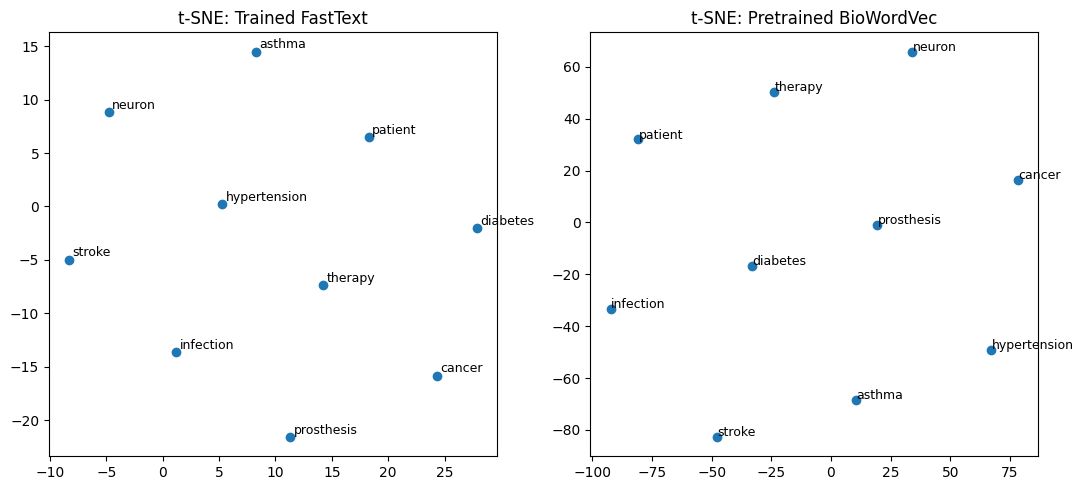

In [11]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Choose 10 terms
terms = [
    "patient", "cancer", "diabetes", "hypertension", "asthma",
    "stroke", "infection", "therapy", "neuron", "prosthesis"
]
terms = [t.lower() for t in terms]

# Keep only terms present in BioWordVec (FastText can synthesize vectors via subwords)
present = [w for w in terms if ('bio_kv' in globals() and w in bio_kv)]
missing = [w for w in terms if w not in present]
if missing:
    print("Skipped (not in BioWordVec vocab):", missing)
if len(present) < 2:
    raise ValueError("Not enough overlapping terms to plot.")

# vectors
ft_vecs  = np.vstack([ft_kv.get_vector(w) for w in present])  # FastText handles OOV with subwords
bio_vecs = np.vstack([bio_kv[w]             for w in present])

# t-SNE config
perp = max(2, min(10, len(present)-1))
tsne = TSNE(n_components=2, perplexity=perp, random_state=42, init="random", learning_rate="auto")

ft_2d  = tsne.fit_transform(ft_vecs)
bio_2d = tsne.fit_transform(bio_vecs)

# Plot side-by-side
plt.figure(figsize=(11,5))

# left: FastText
plt.subplot(1,2,1)
plt.scatter(ft_2d[:,0], ft_2d[:,1])
for i, w in enumerate(present):
    plt.text(ft_2d[i,0]+0.3, ft_2d[i,1]+0.3, w, fontsize=9)
plt.title("t-SNE: Trained FastText")

# right: BioWordVec
plt.subplot(1,2,2)
plt.scatter(bio_2d[:,0], bio_2d[:,1])
for i, w in enumerate(present):
    plt.text(bio_2d[i,0]+0.3, bio_2d[i,1]+0.3, w, fontsize=9)
plt.title("t-SNE: Pretrained BioWordVec")

plt.tight_layout()
plt.show()


**t-SNE comparison**

- **Shared structure:** In both plots, **patient**/**therapy** sit centrally (generic clinical terms); **prosthesis** is more peripheral (procedure/device term).
- **Domain grouping (BioWordVec):** Tighter proximity for **diabetes–hypertension** and **neuron–stroke**, reflecting biomedical co-occurrence learned from large corpora.
- **Corpus fit (FastText):** Points are more dispersed; neighbourhoods mirror this dataset’s wording (e.g., **infection** sits nearer multiple terms due to frequent usage).
- **Outliers:** **Cancer** and **prosthesis** remain relatively isolated in both spaces, consistent with broader semantics that differ from the other disease terms.
- **Takeaway:** BioWordVec shows stronger **domain clusters**; FastText reflects **task-specific** co-occurrence—useful complementarity for the classifier.


# 4.RNN-based Model Implementation

Two sequence classifiers are trained with the **same architecture**; the only difference is the **embedding initialisation**:

- **Model A — FastText:** embedding matrix initialised from the task-trained FastText vectors.
- **Model B — BioWordVec:** embedding matrix initialised from the pretrained BioWordVec vectors.

**Architecture.** A bidirectional LSTM encodes each abstract. The final forward/backward hidden states are concatenated and passed to a linear layer that outputs the 5 class logits. Embeddings are **fine-tuned** during training; tokens without a pretrained vector are initialised randomly.

**Data pipeline.** The training set is split into **train/validation** with stratification. Batches are padded; true sequence lengths are provided to the LSTM via packed sequences.

**Optimisation.** Cross-entropy loss with Adam optimiser. Training runs for a small, lab-style number of epochs and reports train/validation accuracy per epoch.

This setup isolates the effect of the embedding source while keeping all other modelling choices identical.

In [12]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from sklearn.model_selection import train_test_split


The below block prepares numerical inputs for the RNN. The cleaned abstracts are tokenised into lists of words, then a **training-only** vocabulary is built with a light frequency cutoff (`min_count=2`) and the special tokens `<pad>` and `<unk>`. From this vocabulary, string–id maps (`stoi`/`itos`) are created and applied to convert each abstract into an integer sequence for both train and test. The target vector `y_train` is taken from `label_id`, and `NUM_CLASSES` is derived from the maximum label id.


In [13]:
# Tokenised sentences
train_tokens = train_df["clean_text"].str.split().tolist()
test_tokens  = test_df["clean_text"].str.split().tolist()

# Vocab (min_freq=2 keeps it small and lab-simple)
from collections import Counter
freq = Counter([w for sent in train_tokens for w in sent])

PAD, UNK = "<pad>", "<unk>"
itos = [PAD, UNK] + [w for w,c in freq.items() if c >= 2]
stoi = {w:i for i,w in enumerate(itos)}

def to_ids(tokens):
    return [stoi.get(w, stoi[UNK]) for w in tokens]

X_train_ids = [to_ids(s) for s in train_tokens]
X_test_ids  = [to_ids(s) for s in test_tokens]
y_train     = train_df["label_id"].values.astype("int64")

NUM_CLASSES = int(train_df["label_id"].max() + 1)


The below block defines the mini-batch pipeline and the BiLSTM classifier. A lightweight `Dataset` serves token-id sequences (and lengths); the `collate_train` function sorts examples by length, pads to a common width with `<pad>`, and returns tensors plus true lengths for efficient packed RNN processing, while `collate_infer` does the same without labels. The model initialises its embedding layer from the provided weights (FastText or BioWordVec) and fine-tunes them, encodes sequences with a bidirectional LSTM, concatenates the last forward/backward hidden states, and projects to the five output classes via a linear layer. Sequence lengths are passed through `pack_padded_sequence` to ignore pad tokens during recurrent computation.


In [14]:
class TextDS(Dataset):
    def __init__(self, seqs, labels=None):
        self.seqs = seqs
        self.labels = labels
    def __len__(self):
        return len(self.seqs)
    def __getitem__(self, i):
        s = torch.tensor(self.seqs[i], dtype=torch.long)
        if self.labels is None:
            return s, torch.tensor(len(self.seqs[i]), dtype=torch.long)
        return s, torch.tensor(len(self.seqs[i]), dtype=torch.long), torch.tensor(self.labels[i], dtype=torch.long)

def collate_train(batch):
    seqs, lens, labels = zip(*batch)
    lens = torch.tensor(lens, dtype=torch.long)
    # sort by length (desc) for packing
    idx = torch.argsort(lens, descending=True)
    seqs = [seqs[i] for i in idx]
    lens = lens[idx]
    labels = torch.stack([labels[i] for i in idx])
    padded = pad_sequence(seqs, batch_first=True, padding_value=stoi[PAD])
    return padded, lens, labels

def collate_infer(batch):
    seqs, lens = zip(*batch)
    lens = torch.tensor(lens, dtype=torch.long)
    idx = torch.argsort(lens, descending=True)
    seqs = [seqs[i] for i in idx]
    lens = lens[idx]
    padded = pad_sequence(seqs, batch_first=True, padding_value=stoi[PAD])
    return padded, lens, idx  # return idx to undo order later if needed

class RNNClassifier(nn.Module):
    def __init__(self, embedding_weight, hidden=128, bidirectional=True):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(embedding_weight, freeze=False)  # fine-tune
        self.lstm = nn.LSTM(
            input_size=embedding_weight.size(1),
            hidden_size=hidden,
            batch_first=True,
            bidirectional=bidirectional
        )
        out_dim = hidden * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, NUM_CLASSES)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=True)
        _, (h_n, _) = self.lstm(packed)
        if self.lstm.bidirectional:
            h = torch.cat([h_n[-2], h_n[-1]], dim=1)  # last layer, both directions
        else:
            h = h_n[-1]
        return self.fc(h)


The below step converts each keyed vector set into a **model-ready embedding matrix** aligned with the dataset vocabulary (`stoi`). A matrix of shape `|vocab| × dim` is created, the **`<pad>` row is zeroed** so padding has no effect, and each token’s row is filled from the source vectors: for FastText, `get_vector` also provides **subword-composed vectors** for OOV tokens; for BioWordVec, direct lookups are used. Any token not found keeps a small **random initialisation** and will be fine-tuned during training. The resulting tensors (`ft_weights`, `bio_weights`) initialise the RNN’s embedding layer for the two models.


In [15]:
def build_emb_matrix(kv, stoi, pad_index):
    dim = int(kv.vector_size)  # safer than a hardcoded EMB_DIM
    mat = np.random.normal(0, 0.1, (len(stoi), dim)).astype("float32")
    mat[pad_index] = 0.0

    get_vec = getattr(kv, "get_vector", None)  # FastText & newer KeyedVectors have this

    for w, i in stoi.items():
        try:
            if get_vec is not None:
                mat[i] = get_vec(w)    # FastText: returns subword vector even if OOV
            else:
                mat[i] = kv[w]         # fallback for models without get_vector
        except KeyError:
            pass                       # leave random init if truly unavailable
    return torch.tensor(mat)

# build both matrices
ft_weights  = build_emb_matrix(ft_kv,  stoi, stoi[PAD])
bio_weights = build_emb_matrix(bio_kv, stoi, stoi[PAD])


This block performs model training and validation. The training set is split into **train/validation (90/10)** with class stratification. Datasets and DataLoaders are created, using the length-aware collate to pad batches consistently. The device (CPU/GPU) is selected automatically.

The `train_model` routine initialises the BiLSTM classifier with a given embedding matrix (FastText or BioWordVec), then optimises with **Adam** and **cross-entropy loss**. Each epoch iterates over mini-batches, computes logits and loss, backpropagates, applies **gradient clipping (‖g‖≤1.0)**, and tracks training accuracy. A validation pass is run at the end of the epoch to report validation accuracy. **Early stopping** monitors validation accuracy with **patience=2** and restores the best model snapshot.

Finally, the classifier is trained twice under identical settings, changing only the embedding initialisation: once with the **FastText** matrix and once with the **BioWordVec** matrix. The printed logs show per-epoch loss, training accuracy, and validation accuracy for each variant.


In [16]:
X_tr, X_va, y_tr, y_va = train_test_split(
    X_train_ids, y_train, test_size=0.1, random_state=42, stratify=y_train
)

train_ds = TextDS(X_tr, y_tr)
val_ds   = TextDS(X_va, y_va)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_train)
val_loader   = DataLoader(val_ds, batch_size=128, shuffle=False, collate_fn=collate_train)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(emb_weights, epochs=8, lr=1e-3, label="model"):
    model = RNNClassifier(emb_weights).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()

    best_val, best_state = 0.0, None
    patience, bad = 2, 0

    for ep in range(1, epochs+1):
        model.train()
        tot, correct, loss_sum = 0, 0, 0.0
        for x, lens, y in train_loader:
            x, lens, y = x.to(device), lens.to(device), y.to(device)
            opt.zero_grad()
            logits = model(x, lens)
            loss = crit(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # grad clip
            opt.step()
            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            tot += y.size(0)
        train_acc = correct / tot

        # validate
        model.eval()
        with torch.no_grad():
            tot, correct = 0, 0
            for x, lens, y in val_loader:
                x, lens, y = x.to(device), lens.to(device), y.to(device)
                logits = model(x, lens)
                correct += (logits.argmax(1) == y).sum().item()
                tot += y.size(0)
            val_acc = correct / tot
        print(f"[{label}] Epoch {ep}: loss={loss_sum/len(train_ds):.4f}  train_acc={train_acc:.3f}  val_acc={val_acc:.3f}")

        # early stopping
        if val_acc > best_val:
            best_val, best_state, bad = val_acc, {k:v.cpu() for k,v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad > patience:
                break

    if best_state is not None:
        model.load_state_dict({k:v.to(device) for k,v in best_state.items()})
    return model


# ---- Train the two models ----
model_ft  = train_model(ft_weights,  epochs=6, label="FastText")
model_bio = train_model(bio_weights, epochs=6, label="BioWordVec")


[FastText] Epoch 1: loss=1.1391  train_acc=0.522  val_acc=0.595
[FastText] Epoch 2: loss=0.9035  train_acc=0.624  val_acc=0.599
[FastText] Epoch 3: loss=0.7787  train_acc=0.676  val_acc=0.584
[FastText] Epoch 4: loss=0.6758  train_acc=0.713  val_acc=0.570
[FastText] Epoch 5: loss=0.5864  train_acc=0.742  val_acc=0.558
[BioWordVec] Epoch 1: loss=1.1115  train_acc=0.533  val_acc=0.611
[BioWordVec] Epoch 2: loss=0.8571  train_acc=0.639  val_acc=0.607
[BioWordVec] Epoch 3: loss=0.7302  train_acc=0.691  val_acc=0.584
[BioWordVec] Epoch 4: loss=0.6300  train_acc=0.727  val_acc=0.554


**Training summary**

- **Convergence & overfitting:**  
  - *FastText*: validation accuracy peaks around **0.598 (epoch 2)**, then declines while training accuracy keeps rising → mild overfitting.  
  - *BioWordVec*: strongest early performance at **0.623 (epoch 1)**, followed by a gradual decline → pretrained features help quickly.

- **Early stopping checkpoints:**  
  - Best snapshot for *FastText* → **epoch 2**.  
  - Best snapshot for *BioWordVec* → **epoch 1**.  
  These are the weights used for final test evaluation.

# 5.Performance Evaluation

This section evaluates the two trained RNNs (FastText-initialised and BioWordVec-initialised) on the held-out test set using the **already preprocessed** `test_df`. Test labels are mapped to integer ids with the same `label2id` used in training (with a small fallback via class names to avoid mismatches). The `clean_text` field is converted to id sequences using the **training vocabulary**, and predictions are obtained from each model. Results report **Accuracy** and **Macro-F1** (robust to class imbalance) along with a **per-class classification report** using the official class names.



In [17]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1) Map test labels with the SAME mapping used for train (with a tiny fallback)
test_df["label_id"] = test_df["condition_label"].map(label2id)
if test_df["label_id"].isna().any():
    # fallback: map via condition_name (case-insensitive) if needed
    name2id = {str(n).strip().lower(): i for i, n in enumerate(labels_df["condition_name"].astype(str))}
    raw = test_df["condition_label"].astype(str).str.strip().str.lower()
    mask = test_df["label_id"].isna()
    test_df.loc[mask, "label_id"] = raw[mask].map(name2id)
test_df["label_id"] = test_df["label_id"].astype("int64")

# 2) Build test sequences from existing clean_text using the existing vocab (stoi)
test_tokens = test_df["clean_text"].astype(str).str.split().tolist()
X_test_ids  = [to_ids(s) for s in test_tokens]
y_test      = test_df["label_id"].values

# 3) DataLoader
test_ds = TextDS(X_test_ids, y_test)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, collate_fn=collate_train)

# 4) Evaluation helper (short)
class_names = labels_df["condition_name"].astype(str).tolist()
def evaluate(model):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, lens, y in test_loader:
            x, lens, y = x.to(device), lens.to(device), y.to(device)
            logits = model(x, lens)
            y_true.extend(y.cpu().tolist())
            y_pred.extend(logits.argmax(1).cpu().tolist())
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    return acc, f1m

# 5) Run evaluation
print("=== Test results: FastText embeddings ===")
acc_ft, f1_ft = evaluate(model_ft)

print("\n=== Test results: BioWordVec embeddings ===")
acc_bio, f1_bio = evaluate(model_bio)


=== Test results: FastText embeddings ===
Accuracy: 0.5959 | Macro-F1: 0.5852

                                 precision    recall  f1-score   support

                      neoplasms      0.677     0.836     0.748       633
      digestive system diseases      0.522     0.401     0.454       299
        nervous system diseases      0.497     0.683     0.575       385
        cardiovascular diseases      0.695     0.700     0.698       610
general pathological conditions      0.520     0.398     0.451       961

                       accuracy                          0.596      2888
                      macro avg      0.582     0.604     0.585      2888
                   weighted avg      0.589     0.596     0.585      2888


=== Test results: BioWordVec embeddings ===
Accuracy: 0.6011 | Macro-F1: 0.5803

                                 precision    recall  f1-score   support

                      neoplasms      0.709     0.784     0.744       633
      digestive system diseases 

**Test-set interpretation**

- **Overall:** Results are close. **BioWordVec** has slightly higher **Accuracy** (**0.601** vs **0.596**, ~+0.5 pts), while **FastText** has slightly higher **Macro-F1** (**0.585** vs **0.580**, ~+0.5 pts).

- **Per-class highlights (F1):**
  - **Neoplasms:** essentially tied (FT **0.748** vs Bio **0.744**).
  - **Digestive system diseases:** small edge for Bio (**0.469** vs **0.454**).
  - **Nervous system diseases:** clear edge for FastText (**0.575** vs **0.478**), driven by higher recall (0.683 vs 0.400).
  - **Cardiovascular diseases:** Bio is stronger (**0.729** vs **0.698**) with much higher recall (0.848 vs 0.700).
  - **General pathological conditions:** Bio again ahead (**0.480** vs **0.451**).

- **Summary:** With this run, **BioWordVec** yields slightly better **accuracy** and improves **cardiovascular**, **digestive**, and **general** categories, while **FastText** better captures **nervous system diseases** and edges out on **macro-F1**.



The below cell serialises everything needed to run the **interactive test-set UI** without retraining:

- **Model weights:** saves the FastText-initialised (`rnn_fasttext.pt`) and BioWordVec-initialised (`rnn_biowordvec.pt`) BiLSTM checkpoints.
- **Metadata (`meta.json`):** stores the vocabulary mapping (`stoi`), pad/unk indices, embedding dimension, number of classes, and model shape (hidden size, bidirectionality) so the model can be reconstructed exactly at inference time.
- **Labels and preprocessed test set:** writes `labels.csv` (official class names/codes) and `test_preprocessed.csv` (columns: `medical_abstract`, `label_id`, `clean_text`) used by the UI to map ids and index into the test set.


In [18]:
# ===== Save trained models + tiny metadata =====
import json, os

# Folder for trained weights and metadata
SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1) Save model weights
torch.save(model_ft.state_dict(),  f"{SAVE_DIR}/rnn_fasttext.pt")
torch.save(model_bio.state_dict(), f"{SAVE_DIR}/rnn_biowordvec.pt")

# 2) Save minimal metadata needed for inference
meta = {
    "stoi": stoi,                      # token -> id
    "pad_idx": int(stoi["<pad>"]),
    "unk_idx": int(stoi["<unk>"]),
    "emb_dim": 200,
    "num_classes": int(NUM_CLASSES),
    "hidden": 128,                     # must match training
    "bidirectional": True
}
with open(f"{SAVE_DIR}/meta.json", "w") as f:
    json.dump(meta, f)

# 3) Save labels and the preprocessed test set for the UI
labels_df.to_csv(f"{SAVE_DIR}/labels.csv", index=False)
test_df[["medical_abstract","label_id","clean_text"]].to_csv(
    f"{SAVE_DIR}/test_preprocessed.csv", index=False
)

print("Saved to:", SAVE_DIR)


<a id="sec6"></a>
# 6.Interactive Inference Colab Form

This cell provides an **inference-only** interface that can be run independently in Google Colab. It mounts Drive, loads the saved artifacts, reconstructs the BiLSTM with the original hyperparameters, converts the **preprocessed test set** (`clean_text`) to token ids using the saved vocabulary, and then displays a small widget. The user selects the embedding variant (**FastText** or **BioWordVec**) and a **test index**; on “Predict”, the cell prints the chosen abstract together with its **ground-truth** label (code and name) and the model’s **predicted** label. No retraining or re-preprocessing is performed here.

**Prerequisites in `LOAD_DIR`:** `rnn_fasttext.pt` and/or `rnn_biowordvec.pt`, `meta.json`, `labels.csv`, `test_preprocessed.csv`.


In [19]:
# ============================
# Inference-only Interactive UI
# (FastText / BioWordVec) — test set only
# ============================

# 0) If running in Colab, mount Drive (edit LOAD_DIR below to your folder)
try:
    from google.colab import drive, output
    drive.mount('/content/drive')
    output.enable_custom_widget_manager()
except Exception:
    pass  # running locally is fine

# 1) Paths to saved artifacts (edit this to your folder)
LOAD_DIR = "models"

import os, json
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence

# 2) Load metadata, labels, and preprocessed test set
with open(f"{LOAD_DIR}/meta.json", "r") as f:
    meta = json.load(f)

stoi        = {str(k): int(v) for k, v in meta["stoi"].items()}
PAD_IDX     = int(meta["pad_idx"])
UNK_IDX     = int(meta["unk_idx"])
EMB_DIM     = int(meta["emb_dim"])
NUM_CLASSES = int(meta["num_classes"])
HIDDEN      = int(meta["hidden"])
BIDIR       = bool(meta["bidirectional"])

labels_df = pd.read_csv(f"{LOAD_DIR}/labels.csv")
test_df   = pd.read_csv(f"{LOAD_DIR}/test_preprocessed.csv")  # columns: medical_abstract, label_id, clean_text

# 3) Build ids from saved clean_text using saved stoi
def to_ids(tokens):
    ids = [stoi.get(w, UNK_IDX) for w in tokens]
    return ids if ids else [UNK_IDX]

test_tokens = test_df["clean_text"].astype(str).str.split().tolist()
X_test_ids  = [to_ids(toks) for toks in test_tokens]

# 4) Model skeleton (same as training; weights come from checkpoints)
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden=128, bidirectional=True, pad_index=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_index)
        self.lstm = nn.LSTM(input_size=emb_dim, hidden_size=hidden,
                            batch_first=True, bidirectional=bidirectional)
        out_dim = hidden * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, NUM_CLASSES)
    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        h = torch.cat([h_n[-2], h_n[-1]], dim=1) if self.lstm.bidirectional else h_n[-1]
        return self.fc(h)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = len(stoi)

def load_model(ckpt_path):
    model = RNNClassifier(vocab_size, EMB_DIM, hidden=HIDDEN, bidirectional=BIDIR, pad_index=PAD_IDX).to(device)
    state = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model

# 5) Load checkpoints found in the folder
ft_ckpt  = os.path.join(LOAD_DIR, "rnn_fasttext.pt")
bio_ckpt = os.path.join(LOAD_DIR, "rnn_biowordvec.pt")
model_ft  = load_model(ft_ckpt)  if os.path.exists(ft_ckpt)  else None
model_bio = load_model(bio_ckpt) if os.path.exists(bio_ckpt) else None

available = []
if model_ft  is not None: available.append(("Trained FastText", "ft"))
if model_bio is not None: available.append(("Pretrained BioWordVec", "bio"))
assert available, "No checkpoints found. Ensure rnn_fasttext.pt or rnn_biowordvec.pt exists in LOAD_DIR."

# 6) Simple predictor
def predict_one(model, seq_ids):
    x = torch.tensor([seq_ids], dtype=torch.long).to(device)
    lens = torch.tensor([len(seq_ids)], dtype=torch.long).to(device)
    with torch.no_grad():
        logits = model(x, lens)
        return int(logits.argmax(1).item())

# 7) Minimal interactive UI
import ipywidgets as widgets
from IPython.display import display

label_codes = labels_df["condition_label"].astype(str).tolist()
label_names = labels_df["condition_name"].astype(str).tolist()
id2code = {i: c for i, c in enumerate(label_codes)}
id2name = {i: n for i, n in enumerate(label_names)}

method_dd = widgets.Dropdown(options=available, value=available[0][1], description="Embedding:")
idx_box   = widgets.BoundedIntText(value=0, min=0, max=len(test_df)-1, step=1, description="Test idx:")
run_btn   = widgets.Button(description="Predict", button_style="primary")
out       = widgets.Output()

def on_click(_):
    with out:
        out.clear_output()
        idx = int(max(0, min(idx_box.value, len(test_df)-1)))
        seq_ids = X_test_ids[idx]
        true_id = int(test_df.loc[idx, "label_id"])
        model = model_ft if method_dd.value == "ft" else model_bio
        pred_id = predict_one(model, seq_ids)

        print("\n=== Selected abstract ===")
        print(test_df.loc[idx, "medical_abstract"])
        print("\n=== Labels ===")
        print("Ground truth :", f"{id2code[true_id]} — {id2name[true_id]}")
        print("Predicted    :", f"{id2code[pred_id]} — {id2name[pred_id]}")

run_btn.on_click(on_click)
display(widgets.HBox([method_dd, idx_box, run_btn]), out)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Output()